# Model Notebook Template

**How to use this template:**

1. Copy this file and rename it to your notebook name, for example `05_decision_tree_random_forest.ipynb`.
2. In the **Model Settings** cell, change `MODEL_NAME`, the model and `param_grid`.
3. Use `make_scaled_pipeline(...)` for Logistic Regression, Naive Bayes, KNN and SVM. Tree-based models (Decision Tree, Random Forest, XGBoost) do not need scaling, so use the model directly.
4. For slow models (KNN and SVM), set `TUNING_SAMPLE_SIZE = 30000`. Tuning and cross-validation then use a smaller sample, but the final model is still trained on the full training set.
5. Run all cells. The results are saved to `results/metrics/` and the confusion matrices to `results/confusion_matrices/`.
6. If your notebook has two models, repeat sections 1 to 7 for the second model.
7. **Isolation Forest only:** it does not use labels and does not support `GridSearchCV` with F1 in the normal way. Train it on `X_train`, change its output with `(model.predict(X) == -1).astype(int)` so that 1 = Phishing, use `-model.score_samples(X)` as the score, and pass both to `evaluate_predictions(...)` from `src/evaluation.py`.

This example uses Logistic Regression. Delete this cell when you make your own notebook.

# 0X - Model Name

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Train and evaluate the model on the processed PhiUSIIL data, compare different feature sets, and test the URL-only version on the external dataset.

**Input:** `data/processed/`

**Output:** `results/metrics/`, `results/confusion_matrices/`

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [2]:
import sys
import time
from pathlib import Path

import pandas as pd
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

sys.path.append(str(Path("..").resolve()))
from src.data import get_feature_sets, load_train_test, load_url_experiment, sample_rows
from src.evaluation import (
    RANDOM_STATE,
    cross_validate_model,
    evaluate_model,
    make_cv,
    make_scaled_pipeline,
    plot_confusion_matrix,
    save_results,
)

In [3]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 188,296 rows | 69 features
Test set:     47,074 rows | 69 features


## Model Settings

We choose the model, the settings we want to try during tuning, and the sample size for tuning.

In [5]:

MODEL_NAME = "KNN"

model = make_scaled_pipeline(
    KNeighborsClassifier(n_jobs=-1)
)

param_grid = {
    "kneighborsclassifier__n_neighbors": [3, 5, 7, 11],
    "kneighborsclassifier__weights": ["uniform", "distance"],
}

TUNING_SAMPLE_SIZE = 30000


## 1. Hyperparameter Tuning

We try each combination of settings in `param_grid` using 3-fold cross-validation on the training set, and keep the one with the best F1-score. The test set is not used here.

In [6]:
X_tune, y_tune = sample_rows(X_train, y_train, TUNING_SAMPLE_SIZE)

search = GridSearchCV(model, param_grid, scoring="f1", cv=make_cv(3), n_jobs=-1)
search.fit(X_tune, y_tune)
best_model = search.best_estimator_

print(f"Best settings: {search.best_params_}")
print(f"Best cross-validation F1: {search.best_score_:.4f}")

Best settings: {'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'distance'}
Best cross-validation F1: 0.9983


## 2. Cross-Validation

We check the best model with 5-fold stratified cross-validation. The mean shows the usual score, and the standard deviation (Std) shows how stable the model is. A small Std means the model gives similar results on different parts of the data.

In [7]:
cv_results = cross_validate_model(best_model, X_tune, y_tune)
cv_results.round(4)

,Mean,Std
Accuracy,0.9988,0.0003
Precision,0.9999,0.0002
Recall,0.9973,0.0006
F1,0.9986,0.0003
ROC-AUC,0.9994,0.0004


## 3. Final Test

We train the best model on the full training set and test it once on the test set. This is the score we report for this model.

In [8]:
start = time.perf_counter()
final_model = clone(best_model).fit(X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_model(final_model, X_test, y_test)
print(f"Training time: {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Training time: 0.9 seconds


,Test Score
Accuracy,0.9993
Precision,0.9999
Recall,0.9985
F1,0.9992
ROC-AUC,0.9997


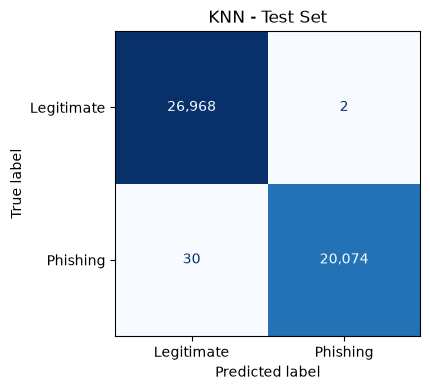

In [9]:
plot_confusion_matrix(y_test, final_model.predict(X_test), f"{MODEL_NAME} - Test Set")

## 4. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work well without its strongest feature?

In [10]:
feature_results = {"All features": test_results}

for set_name in ["Original features only", "Without URLSimilarityIndex"]:
    features = feature_sets[set_name]
    set_model = clone(best_model).fit(X_train[features], y_train)
    feature_results[set_name] = evaluate_model(set_model, X_test[features], y_test)

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
All features,0.9993,0.9999,0.9985,0.9992,0.9997
Original features only,0.9994,0.9999,0.9988,0.9994,0.9998
Without URLSimilarityIndex,0.9993,0.9999,0.9985,0.9992,0.9997


## 5. Experiment 2: URL Features Only

Here the model only uses the 18 URL features that we can create from any URL. We train it on PhiUSIIL and test it on both the PhiUSIIL test set and the external dataset. The difference between the two scores shows how well the model works on data from a different source.

In [11]:
X_url_train, X_url_test, X_external, y_url_train, y_url_test, y_external = load_url_experiment()

url_model = clone(best_model).fit(X_url_train, y_url_train)
url_results = {
    "PhiUSIIL test set": evaluate_model(url_model, X_url_test, y_url_test),
    "External dataset": evaluate_model(url_model, X_external, y_external),
}
pd.DataFrame(url_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
PhiUSIIL test set,0.9949,0.9969,0.9912,0.9941,0.9961
External dataset,0.5024,0.5029,0.9928,0.6676,0.4992


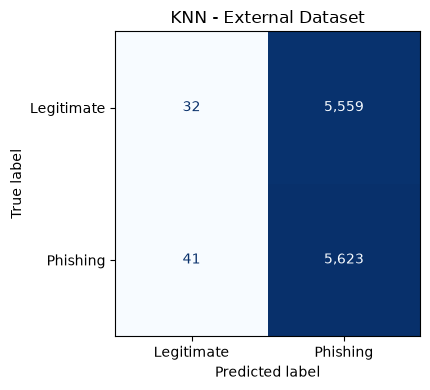

In [12]:
plot_confusion_matrix(y_external, url_model.predict(X_external), f"{MODEL_NAME} - External Dataset")

In [13]:
print("External actual labels:")
print(y_external.value_counts())

print("\nExternal predicted labels:")
external_predictions = url_model.predict(X_external)
print(pd.Series(external_predictions).value_counts())

External actual labels:
label
1    5664
0    5591
Name: count, dtype: int64

External predicted labels:
1    11182
0       73
Name: count, dtype: int64


In [14]:
print("Training URL features:")
print(X_url_train.columns.tolist())

print("\nExternal URL features:")
print(X_external.columns.tolist())

print("\nAre the columns in the same order?")
print(X_url_train.columns.equals(X_external.columns))

print("\nTraining shape:", X_url_train.shape)
print("External shape:", X_external.shape)

Training URL features:
['FullURLLength', 'HostLength', 'PathLength', 'QueryLength', 'PathDepth', 'NoOfDotsInURL', 'NoOfHyphensInURL', 'NoOfSlashesInURL', 'NoOfDigitsInHost', 'HostSubdomainCount', 'SuspiciousWordCount', 'URLEntropy', 'HostEntropy', 'HasAtSymbol', 'HasHTTPSScheme', 'HostIsIP', 'HostHasHyphen', 'HasDoubleSlashInPath']

External URL features:
['FullURLLength', 'HostLength', 'PathLength', 'QueryLength', 'PathDepth', 'NoOfDotsInURL', 'NoOfHyphensInURL', 'NoOfSlashesInURL', 'NoOfDigitsInHost', 'HostSubdomainCount', 'SuspiciousWordCount', 'URLEntropy', 'HostEntropy', 'HasAtSymbol', 'HasHTTPSScheme', 'HostIsIP', 'HostHasHyphen', 'HasDoubleSlashInPath']

Are the columns in the same order?
True

Training shape: (188296, 18)
External shape: (11255, 18)


In [15]:
print("Training dataset statistics:")
display(X_url_train.describe().round(3))

print("\nExternal dataset statistics:")
display(X_external.describe().round(3))

Training dataset statistics:


,FullURLLength,HostLength,PathLength,QueryLength,PathDepth,NoOfDotsInURL,NoOfHyphensInURL,NoOfSlashesInURL,NoOfDigitsInHost,HostSubdomainCount,SuspiciousWordCount,URLEntropy,HostEntropy,HasAtSymbol,HasHTTPSScheme,HostIsIP,HostHasHyphen,HasDoubleSlashInPath
count,188296.000,188296.000,188296.000,188296.000,188296.000,188296.000,188296.000,188296.000,188296.000,188296.000,188296.000,188296.000,188296.000,188296.000,188296.000,188296.000,188296.000,188296.000
mean,35.409,21.468,3.735,2.241,0.251,2.258,0.352,2.434,0.882,1.161,0.048,3.960,3.471,0.006,0.780,0.003,0.176,0.002
std,43.558,9.146,25.263,25.525,0.877,0.944,1.637,1.047,2.792,0.602,0.295,0.315,0.401,0.080,0.414,0.051,0.381,0.042
min,14.000,4.000,0.000,0.000,0.000,1.000,0.000,2.000,0.000,0.000,0.000,2.309,0.722,0.000,0.000,0.000,0.000,0.000
25%,24.000,16.000,0.000,0.000,0.000,2.000,0.000,2.000,0.000,1.000,0.000,3.762,3.203,0.000,1.000,0.000,0.000,0.000
50%,28.000,20.000,0.000,0.000,0.000,2.000,0.000,2.000,0.000,1.000,0.000,3.929,3.471,0.000,1.000,0.000,0.000,0.000
75%,35.000,24.000,1.000,0.000,0.000,2.000,0.000,3.000,0.000,1.000,0.000,4.100,3.720,0.000,1.000,0.000,0.000,0.000
max,6097.000,110.000,4248.000,3391.000,33.000,99.000,286.000,68.000,44.000,10.000,6.000,5.335,4.975,1.000,1.000,1.000,1.000,1.000



External dataset statistics:


,FullURLLength,HostLength,PathLength,QueryLength,PathDepth,NoOfDotsInURL,NoOfHyphensInURL,NoOfSlashesInURL,NoOfDigitsInHost,HostSubdomainCount,SuspiciousWordCount,URLEntropy,HostEntropy,HasAtSymbol,HasHTTPSScheme,HostIsIP,HostHasHyphen,HasDoubleSlashInPath
count,11255.000,11255.000,11255.000,11255.000,11255.000,11255.000,11255.00,11255.000,11255.000,11255.000,11255.000,11255.000,11255.000,11255.000,11255.000,11255.000,11255.000,11255.000
mean,61.564,21.128,23.412,9.236,1.851,2.486,1.01,4.304,0.631,1.035,0.244,4.196,3.463,0.022,0.383,0.009,0.154,0.003
std,55.574,10.830,27.811,44.784,1.888,1.378,2.10,1.889,2.562,0.867,0.683,0.355,0.383,0.146,0.486,0.092,0.361,0.052
min,12.000,4.000,0.000,0.000,0.000,1.000,0.00,2.000,0.000,0.000,0.000,2.953,0.722,0.000,0.000,0.000,0.000,0.000
25%,33.000,15.000,1.000,0.000,0.000,2.000,0.00,3.000,0.000,1.000,0.000,3.965,3.221,0.000,0.000,0.000,0.000,0.000
50%,48.000,19.000,18.000,0.000,2.000,2.000,0.00,4.000,0.000,1.000,0.000,4.168,3.461,0.000,0.000,0.000,0.000,0.000
75%,72.000,24.000,33.000,0.000,3.000,3.000,1.00,5.000,0.000,1.000,0.000,4.408,3.722,0.000,1.000,0.000,0.000,0.000
max,1641.000,214.000,602.000,1585.000,27.000,24.000,43.00,33.000,48.000,13.000,6.000,5.298,5.055,1.000,1.000,1.000,1.000,1.000


In [16]:
print("Training labels:")
print(y_url_train.value_counts())

print("\nTraining label proportions:")
print(y_url_train.value_counts(normalize=True).round(4))

print("\nExternal labels:")
print(y_external.value_counts())

print("\nExternal label proportions:")
print(y_external.value_counts(normalize=True).round(4))

Training labels:
label
0    107880
1     80416
Name: count, dtype: int64

Training label proportions:
label
0    0.5729
1    0.4271
Name: proportion, dtype: float64

External labels:
label
1    5664
0    5591
Name: count, dtype: int64

External label proportions:
label
1    0.5032
0    0.4968
Name: proportion, dtype: float64


In [17]:
print("KNN model pipeline:")
print(best_model)

print("\nPipeline steps:")
print(best_model.named_steps)

KNN model pipeline:
Pipeline(steps=[('functiontransformer',
                 FunctionTransformer(feature_names_out='one-to-one',
                                     func=<ufunc 'log1p'>)),
                ('standardscaler', StandardScaler()),
                ('kneighborsclassifier',
                 KNeighborsClassifier(n_jobs=-1, n_neighbors=3,
                                      weights='distance'))])

Pipeline steps:
{'functiontransformer': FunctionTransformer(feature_names_out='one-to-one', func=<ufunc 'log1p'>), 'standardscaler': StandardScaler(), 'kneighborsclassifier': KNeighborsClassifier(n_jobs=-1, n_neighbors=3, weights='distance')}


## 6. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [ ]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
    {"Experiment": "URL features - PhiUSIIL test set", **url_results["PhiUSIIL test set"]},
    {"Experiment": "URL features - External dataset", **url_results["External dataset"]},
]

save_results(MODEL_NAME, results).round(4)

## 7. Findings

Write the findings for this model here after running the notebook. For example:

- How good is the test score, and how stable is the cross-validation score?
- Did the new features help?
- How much did the score change without `URLSimilarityIndex`?
- How much did the score drop on the external dataset, and why?